In [45]:
import polars as pl
e= pl.read_parquet("enappsys_data.parquet")
e= e.select(pl.col("delivery_start").dt.convert_time_zone("UTC"), pl.col("residual_load_entsoe_fcs").alias("entsoe"),pl.col("residual_load_fcs").alias("enappsys"))
ew = pl.read_parquet("energy_weather_data.parquet")
ew = ew.select(pl.col("delivery_start").dt.convert_time_zone("UTC"), pl.col("residual_load_fcs").alias("energy_weather"))
k = pl.read_parquet("kpler_data.parquet")
ta = pl.read_parquet("tech_avail.parquet").select(pl.col("time").dt.convert_time_zone("UTC"), pl.col("residual load tech avail").alias("tech_avail"))





In [46]:
result = (
    e
    .join(
        ew,
        on="delivery_start",
        how="outer",
        suffix="_ew"
    )
    .join(
        k,
        left_on="delivery_start",
        right_on="time",
        how="outer",
        suffix="_k"
    )
    .join(
        ta,
        left_on="delivery_start",
        right_on="time",
        how="outer",
        suffix="_ta"
    )
    .sort("delivery_start")
)

C:\Users\HanhTa\AppData\Local\Temp\ipykernel_25816\119295846.py:3: DeprecationWarning: use of `how='outer'` should be replaced with `how='full'`.
(Deprecated in version 0.20.29)
  .join(
C:\Users\HanhTa\AppData\Local\Temp\ipykernel_25816\119295846.py:9: DeprecationWarning: use of `how='outer'` should be replaced with `how='full'`.
(Deprecated in version 0.20.29)
  .join(
C:\Users\HanhTa\AppData\Local\Temp\ipykernel_25816\119295846.py:16: DeprecationWarning: use of `how='outer'` should be replaced with `how='full'`.
(Deprecated in version 0.20.29)
  .join(


In [47]:
display(result)

delivery_start,entsoe,enappsys,delivery_start_ew,energy_weather,time,GFS_ENS,EC_OP,EC_46,GFS_OP,EC_AIFS,EC_ENS,EC_AIFS_ENS,time_ta,tech_avail
"datetime[μs, UTC]",f64,f64,"datetime[μs, UTC]",f64,"datetime[μs, UTC]",f64,f64,f64,f64,f64,f64,f64,"datetime[μs, UTC]",f64
null,null,null,null,null,2026-08-31 22:00:00 UTC,7095.2,12485.7,12623.23,7692.19,17071.89,10139.39,14249.75,null,null
null,null,null,null,null,2026-08-31 22:15:00 UTC,6770.99,10903.99,12014.95,6747.56,16330.05,9688.25,13545.32,null,null
null,null,null,null,null,2026-08-31 22:30:00 UTC,6386.53,10825.84,11432.04,6021.6,15649.31,9250.15,12964.8,null,null
null,null,null,null,null,2026-08-31 22:45:00 UTC,6507.58,11014.7,11508.76,5842.26,15612.46,9412.95,13033.12,null,null
null,null,null,null,null,2026-08-31 23:00:00 UTC,5775.61,10199.55,10634.15,4781.0,14707.21,8650.14,12082.74,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2026-08-31 20:45:00 UTC,null,18895.0,null,null,2026-08-31 20:45:00 UTC,11307.6,17793.99,16925.59,11666.43,21455.2,15201.42,18787.84,2026-08-31 20:45:00 UTC,23430.036004
2026-08-31 21:00:00 UTC,null,18243.0,null,null,2026-08-31 21:00:00 UTC,10169.22,16473.27,15840.1,10332.86,20674.2,13933.58,17671.82,2026-08-31 21:00:00 UTC,21981.179726
2026-08-31 21:15:00 UTC,null,17943.0,null,null,2026-08-31 21:15:00 UTC,9907.98,15666.93,15589.86,9764.63,20468.71,13468.25,17365.42,2026-08-31 21:15:00 UTC,21056.144538


In [48]:
result = (
    result
    .with_columns(
        pl.coalesce([
            pl.col("delivery_start"),
            pl.col("delivery_start_ew"),
            pl.col("time"),
            pl.col("time_ta")
        ]).alias("delivery_start")
    )
    .select([
        "delivery_start",
        pl.col("entsoe").alias("entsoe"),
        pl.col("enappsys").alias("enappsys"),
        pl.col("energy_weather"),
        pl.col("GFS_ENS"),
        pl.col("EC_OP"),
        pl.col("EC_46"),
        pl.col("GFS_OP"),
        pl.col("EC_AIFS"),
        pl.col("EC_ENS"),
        pl.col("EC_AIFS_ENS"),
        pl.col("tech_avail")
    ])
    .sort("delivery_start")
)

display(result)

delivery_start,entsoe,enappsys,energy_weather,GFS_ENS,EC_OP,EC_46,GFS_OP,EC_AIFS,EC_ENS,EC_AIFS_ENS,tech_avail
"datetime[μs, UTC]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2025-12-31 23:00:00 UTC,12073.0,17594.0,null,null,null,null,null,null,null,null,null
2025-12-31 23:15:00 UTC,10821.0,16404.0,null,null,null,null,null,null,null,null,null
2025-12-31 23:30:00 UTC,10246.0,15619.0,null,null,null,null,null,null,null,null,null
2025-12-31 23:45:00 UTC,9326.0,14055.0,null,null,null,null,null,null,null,null,null
2026-01-01 00:00:00 UTC,8469.0,10310.0,null,6870.44,6489.05,10183.42,3739.45,8379.26,7036.98,null,-2660.471509
…,…,…,…,…,…,…,…,…,…,…,…
2026-09-24 22:45:00 UTC,null,null,null,35236.9,38660.26,null,38208.69,39552.65,38087.53,39000.34,null
2026-09-24 23:00:00 UTC,null,null,null,34688.72,38078.54,null,37823.31,39620.27,37434.19,38480.48,null
2026-09-24 23:15:00 UTC,null,null,null,34240.7,37509.9,null,36908.4,39106.95,36866.27,38042.28,null


In [49]:
result = result.filter(
    (pl.col("delivery_start") >= pl.datetime(2026, 1, 1, time_zone="UTC")) &
    (pl.col("delivery_start") < pl.datetime(2026, 9, 1, time_zone="UTC"))
)

print(result)

shape: (25_452, 12)
┌─────────────┬────────┬──────────┬─────────────┬───┬──────────┬─────────┬────────────┬────────────┐
│ delivery_st ┆ entsoe ┆ enappsys ┆ energy_weat ┆ … ┆ EC_AIFS  ┆ EC_ENS  ┆ EC_AIFS_EN ┆ tech_avail │
│ art         ┆ ---    ┆ ---      ┆ her         ┆   ┆ ---      ┆ ---     ┆ S          ┆ ---        │
│ ---         ┆ f64    ┆ f64      ┆ ---         ┆   ┆ f64      ┆ f64     ┆ ---        ┆ f64        │
│ datetime[μs ┆        ┆          ┆ f64         ┆   ┆          ┆         ┆ f64        ┆            │
│ , UTC]      ┆        ┆          ┆             ┆   ┆          ┆         ┆            ┆            │
╞═════════════╪════════╪══════════╪═════════════╪═══╪══════════╪═════════╪════════════╪════════════╡
│ 2026-01-01  ┆ 8469.0 ┆ 10310.0  ┆ null        ┆ … ┆ 8379.26  ┆ 7036.98 ┆ null       ┆ -2660.4715 │
│ 00:00:00    ┆        ┆          ┆             ┆   ┆          ┆         ┆            ┆ 09         │
│ UTC         ┆        ┆          ┆             ┆   ┆          ┆       

In [50]:
result.write_parquet("forecast_result.parquet")


In [66]:
#1 : stats
# Difference-overtime-plots 
descibe = result.describe()
# ~pl.col : NOT
stats =descibe.select("statistic","entsoe","enappsys","energy_weather", "EC_ENS","tech_avail").filter(~pl.col("statistic").is_in(["null_count","25%","75%"]))

# there is a string column : statistic => unable to round whole dataframe => select numeric columns, or use pl.col(pl.NUMERIC_DTYPES).round(2)--- doesnt work here
stats =stats.with_columns(pl.col("enappsys","entsoe","energy_weather","EC_ENS","tech_avail").round(2))
display(stats)


statistic,entsoe,enappsys,energy_weather,EC_ENS,tech_avail
str,f64,f64,f64,f64,f64
"""count""",17264.0,24625.0,19304.0,25444.0,25444.0
"""mean""",28707.56,28285.98,28739.33,26175.88,27479.85
"""std""",15942.11,18070.46,18557.75,17703.71,18941.54
"""min""",-12185.0,-37827.0,-42249.38,-48711.21,-54246.7
"""50%""",31211.0,31705.0,32713.83,29451.46,31075.89
"""max""",67181.0,74847.0,67764.26,64922.23,66588.53


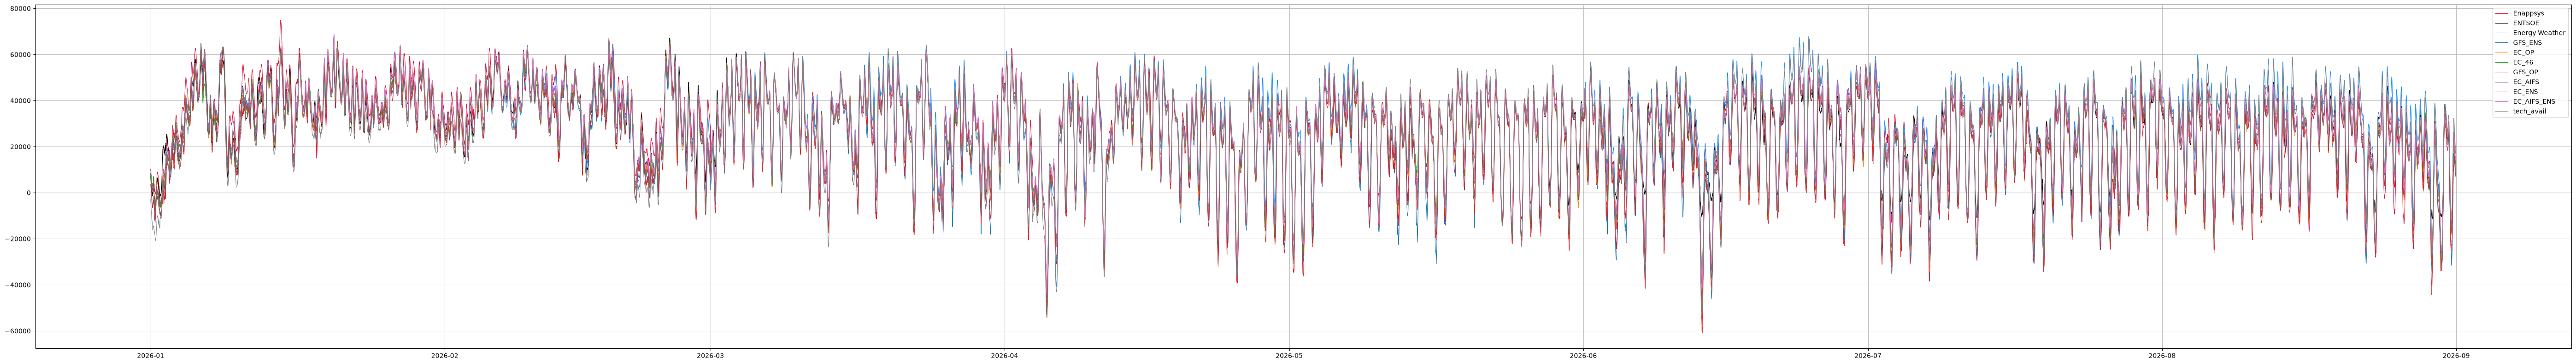

In [52]:
#line entsoe, enappsys, energy weather, 7 kpler models, techavail
import matplotlib.pyplot as plt
plt.figure(figsize=(56,8))

#main series
plt.plot(
    result["delivery_start"],
    result["enappsys"],
    color="crimson",
    linewidth=0.8,
    label="Enappsys"

)


plt.plot(
    result["delivery_start"],
    result["entsoe"],
    color="black",
    linewidth= 0.8,
    label="ENTSOE"
)

plt.plot(
    result["delivery_start"],
    result["energy_weather"],
    color="dodgerblue",
    linewidth=0.8,
    label="Energy Weather"

)

for cols in result.columns[4:]:
  plt.plot(
     result["delivery_start"],result[cols],
     linewidth=0.8,
     label=cols,
     
)
plt.grid(alpha= 0.8)
plt.tight_layout()
plt.legend()
plt.show()

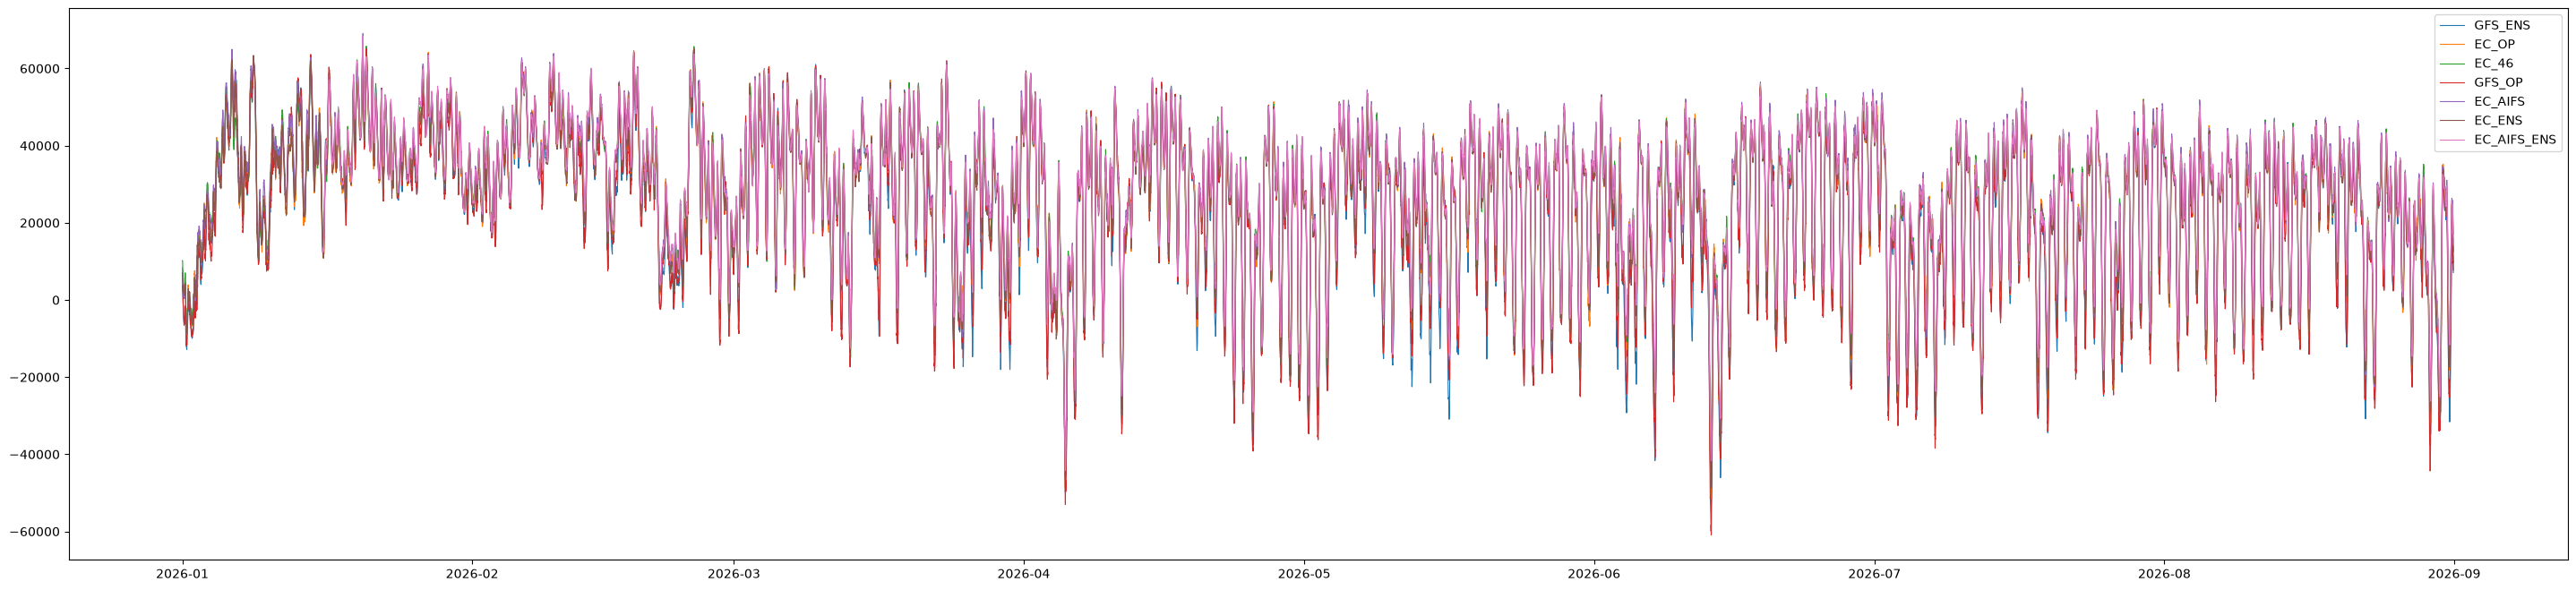

In [53]:
#lines 7 kpler models
plt.figure(figsize=(36,8))
for cols in result.columns[4:11]:
  plt.plot(
     result["delivery_start"],result[cols],
     linewidth=0.8,
     label=cols,
     
)

plt.legend()
plt.show()


In [54]:
#line entsoe, anappsys, energy weather,  1kpler model



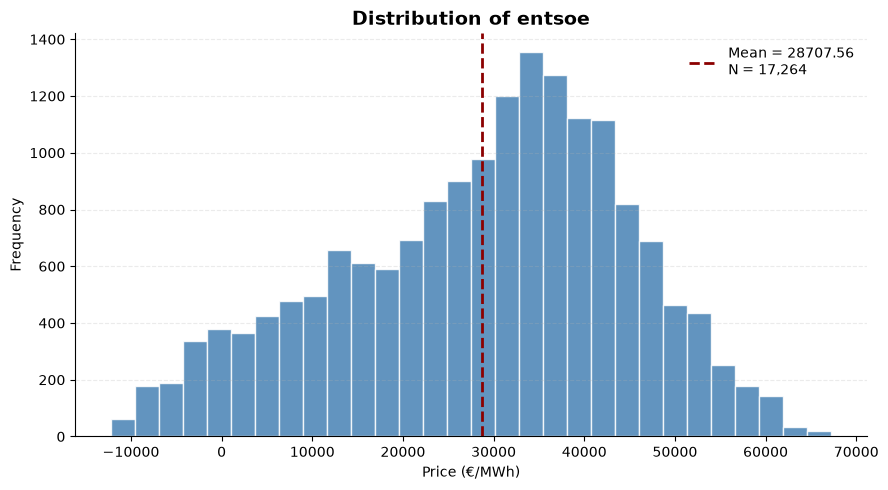

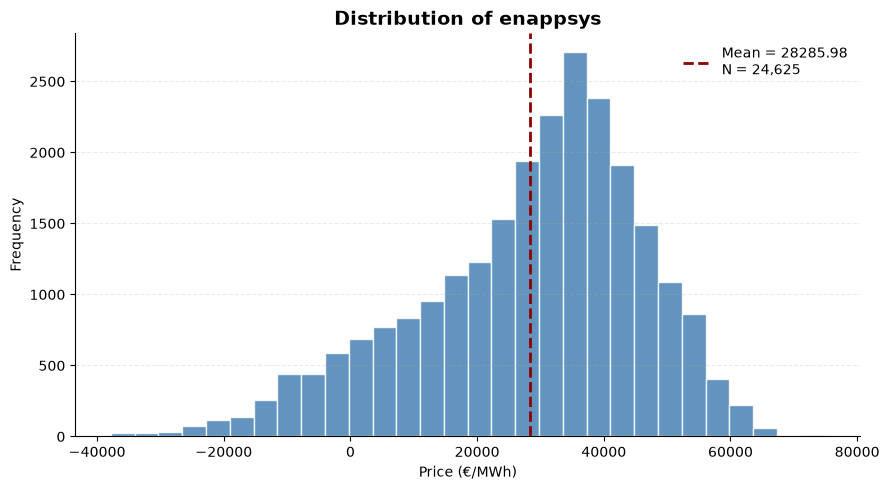

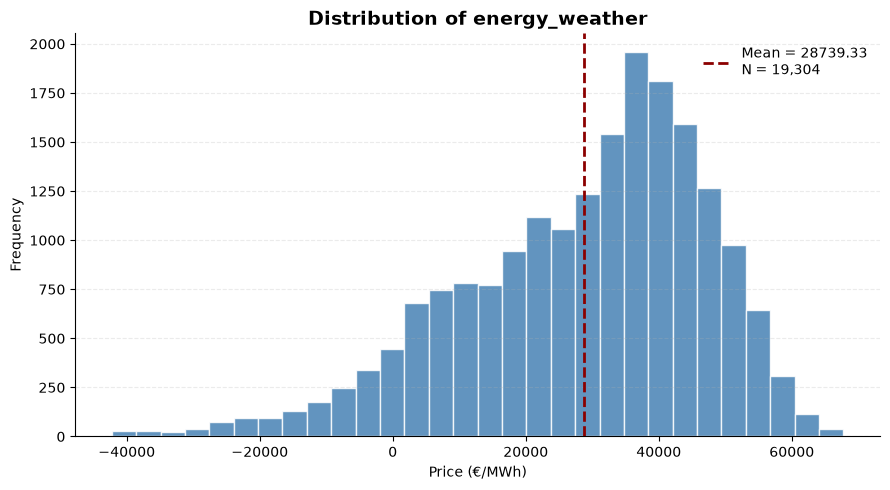

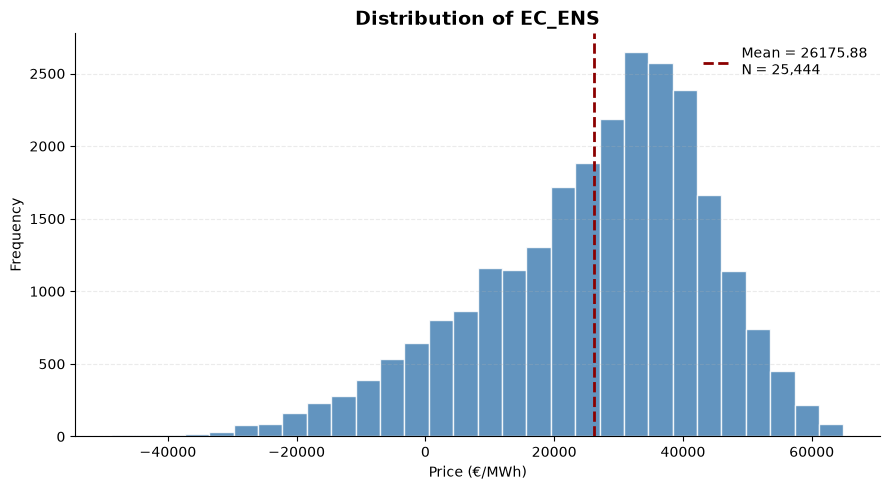

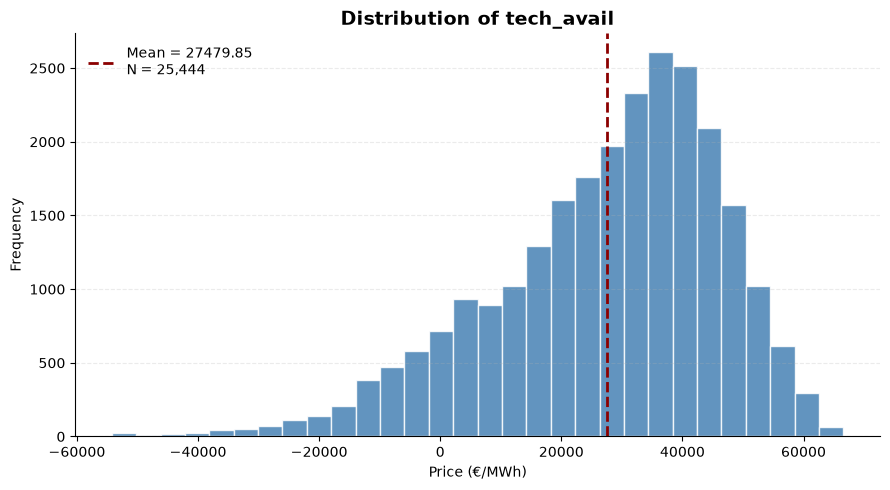

In [55]:
# histogram

import matplotlib.pyplot as plt

providers = ["entsoe", "enappsys", "energy_weather","EC_ENS","tech_avail"]

for col in providers:
    data = result[col].drop_nulls().to_numpy()
    mean = data.mean()
    n = len(data)

    plt.figure(figsize=(9, 5))

    plt.hist(
        data,
        bins=30,
        color="steelblue",
        edgecolor="white",
        alpha=0.85
    )

    # Mean line
    plt.axvline(
        mean,
        color="darkred",
        linestyle="--",
        linewidth=2,
        label=f"Mean = {mean:.2f}\nN = {n:,}"
    )

    plt.title(
        f"Distribution of {col}",
        fontsize=14,
        fontweight="bold"
    )

    plt.xlabel("Price (€/MWh)")
    plt.ylabel("Frequency")

    plt.grid(axis="y", alpha=0.25, linestyle="--")
    plt.legend(frameon=False)

    plt.gca().spines["top"].set_visible(False)
    plt.gca().spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()

In [56]:
#4: bias matrix : Bias (A,B) = mean(A-B) ; who is systematically above or below whom? (systematic overestimation/ underestimation), value close to 0 means no systematic errors.
# dictionary row becomes a row in dataframe
import polars as pl

forecasts = ["entsoe","enappsys","energy_weather","EC_ENS","tech_avail"]

rows = []

for a in forecasts:
    row = {"forecast": a}

    for b in forecasts:
        if a == b:
            row[b] = 0.0
        else:
            row[b] = (result[a] - result[b]).mean()

    rows.append(row)

bias_matrix = pl.DataFrame(rows)

print(bias_matrix)

shape: (5, 6)
┌────────────────┬──────────────┬──────────────┬────────────────┬─────────────┬─────────────┐
│ forecast       ┆ entsoe       ┆ enappsys     ┆ energy_weather ┆ EC_ENS      ┆ tech_avail  │
│ ---            ┆ ---          ┆ ---          ┆ ---            ┆ ---         ┆ ---         │
│ str            ┆ f64          ┆ f64          ┆ f64            ┆ f64         ┆ f64         │
╞════════════════╪══════════════╪══════════════╪════════════════╪═════════════╪═════════════╡
│ entsoe         ┆ 0.0          ┆ -463.844834  ┆ -2291.870907   ┆ 1540.010153 ┆ 85.859843   │
│ enappsys       ┆ 463.844834   ┆ 0.0          ┆ -2571.412084   ┆ 1849.067469 ┆ 366.007257  │
│ energy_weather ┆ 2291.870907  ┆ 2571.412084  ┆ 0.0            ┆ 3793.939188 ┆ 2094.484802 │
│ EC_ENS         ┆ -1540.010153 ┆ -1849.067469 ┆ -3793.939188   ┆ 0.0         ┆ -1301.54721 │
│ tech_avail     ┆ -85.859843   ┆ -366.007257  ┆ -2094.484802   ┆ 1301.54721  ┆ 0.0         │
└────────────────┴──────────────┴─────────────

In [57]:
# Correlation of forecast level:
# Do the providers' forecasts generally move together?
level_corr = (
    result
    .select(forecast_cols)
    .drop_nulls()   
    .corr()
    .with_columns(
        pl.Series("provider", forecast_cols)
    )
    .select(["provider"] + forecast_cols)
)

display(level_corr)

provider,entsoe,enappsys,energy_weather,EC_ENS,tech_avail
str,f64,f64,f64,f64,f64
"""entsoe""",1.0,0.952519,0.92911,0.975676,0.940984
"""enappsys""",0.952519,1.0,0.936385,0.961876,0.920953
"""energy_weather""",0.92911,0.936385,1.0,0.953184,0.982289
"""EC_ENS""",0.975676,0.961876,0.953184,1.0,0.963495
"""tech_avail""",0.940984,0.920953,0.982289,0.963495,1.0


In [58]:
# qoq : quarter on quarter difference correlation

import polars as pl

providers = [
    "entsoe",
    "enappsys",
    "energy_weather",
    "EC_ENS",
    "tech_avail"
]

qoq = (
    result
    .sort("delivery_start")
    .select(
        "delivery_start",
        *[
            pl.when(
                pl.col("delivery_start").diff() == pl.duration(minutes=15)
            )
            .then(pl.col(col).diff())
            .otherwise(None)
            .alias(f"delta_{col}")
            for col in providers
        ]
    )
)

qoq


delivery_start,delta_entsoe,delta_enappsys,delta_energy_weather,delta_EC_ENS,delta_tech_avail
"datetime[μs, UTC]",f64,f64,f64,f64,f64
2026-01-01 00:00:00 UTC,null,null,null,null,null
2026-01-01 00:15:00 UTC,-1261.0,-853.0,null,-718.02,-1068.600035
2026-01-01 00:30:00 UTC,-910.0,-374.0,null,-917.27,-912.785904
2026-01-01 00:45:00 UTC,-494.0,-772.0,null,-466.5,-818.462651
2026-01-01 01:00:00 UTC,-828.0,-256.0,null,-100.35,-733.699756
…,…,…,…,…,…
2026-08-31 23:15:00 UTC,null,null,null,null,null
2026-08-31 23:30:00 UTC,null,null,null,null,null
2026-08-31 23:30:00 UTC,null,null,null,null,null


In [59]:
qoq = qoq.with_columns(
    pl.col("delivery_start")
    .dt.minute()
    .alias("quarter")
)
delta_cols = [
    "delta_entsoe",
    "delta_enappsys",
    "delta_energy_weather",
    "delta_EC_ENS",
    "delta_tech_avail"
]
qoq


delivery_start,delta_entsoe,delta_enappsys,delta_energy_weather,delta_EC_ENS,delta_tech_avail,quarter
"datetime[μs, UTC]",f64,f64,f64,f64,f64,i8
2026-01-01 00:00:00 UTC,null,null,null,null,null,0
2026-01-01 00:15:00 UTC,-1261.0,-853.0,null,-718.02,-1068.600035,15
2026-01-01 00:30:00 UTC,-910.0,-374.0,null,-917.27,-912.785904,30
2026-01-01 00:45:00 UTC,-494.0,-772.0,null,-466.5,-818.462651,45
2026-01-01 01:00:00 UTC,-828.0,-256.0,null,-100.35,-733.699756,0
…,…,…,…,…,…,…
2026-08-31 23:15:00 UTC,null,null,null,null,null,15
2026-08-31 23:30:00 UTC,null,null,null,null,null,30
2026-08-31 23:30:00 UTC,null,null,null,null,null,30


In [60]:
corr_matrices = {}

for quarter in [0, 15, 30, 45]:

    data = (
        qoq
        .filter(pl.col("quarter") == quarter)
        .select(delta_cols)
    )

    corr_data = {}

    for col1 in delta_cols:

        correlations = []

        for col2 in delta_cols:

            if col1 == col2:
                corr = 1.0

            else:
                pair = (
                    data
                    .select([col1, col2])
                    .drop_nulls()
                )

                if pair.height >= 2:
                    corr = pair.select(
                        pl.corr(col1, col2)
                    ).item()
                else:
                    corr = None

            correlations.append(corr)

        corr_data[col1] = correlations

    corr_matrix = (
        pl.DataFrame(corr_data)
        .insert_column(
            0,
            pl.Series("provider", delta_cols)
        )
    )

    # save each matrix
    corr_matrices[quarter] = corr_matrix
    quarter_names = {
    0: "Quarter 00 (:45 → :00)",
    15: "Quarter 15 (:00 → :15)",
    30: "Quarter 30 (:15 → :30)",
    45: "Quarter 45 (:30 → :45)"
}

for quarter, matrix in corr_matrices.items():
    print(quarter_names[quarter])
    display(matrix)



Quarter 00 (:45 → :00)


provider,delta_entsoe,delta_enappsys,delta_energy_weather,delta_EC_ENS,delta_tech_avail
str,f64,f64,f64,f64,f64
"""delta_entsoe""",1.0,0.72501,0.820125,0.828643,0.840524
"""delta_enappsys""",0.72501,1.0,0.768757,0.707894,0.762353
"""delta_energy_weather""",0.820125,0.768757,1.0,0.818514,0.945609
"""delta_EC_ENS""",0.828643,0.707894,0.818514,1.0,0.826769
"""delta_tech_avail""",0.840524,0.762353,0.945609,0.826769,1.0


Quarter 15 (:00 → :15)


provider,delta_entsoe,delta_enappsys,delta_energy_weather,delta_EC_ENS,delta_tech_avail
str,f64,f64,f64,f64,f64
"""delta_entsoe""",1.0,0.800014,0.902587,0.805944,0.908923
"""delta_enappsys""",0.800014,1.0,0.861023,0.761101,0.847723
"""delta_energy_weather""",0.902587,0.861023,1.0,0.87956,0.970613
"""delta_EC_ENS""",0.805944,0.761101,0.87956,1.0,0.869967
"""delta_tech_avail""",0.908923,0.847723,0.970613,0.869967,1.0


Quarter 30 (:15 → :30)


provider,delta_entsoe,delta_enappsys,delta_energy_weather,delta_EC_ENS,delta_tech_avail
str,f64,f64,f64,f64,f64
"""delta_entsoe""",1.0,0.798797,0.898789,0.813656,0.906805
"""delta_enappsys""",0.798797,1.0,0.862083,0.779462,0.857759
"""delta_energy_weather""",0.898789,0.862083,1.0,0.879078,0.971435
"""delta_EC_ENS""",0.813656,0.779462,0.879078,1.0,0.881213
"""delta_tech_avail""",0.906805,0.857759,0.971435,0.881213,1.0


Quarter 45 (:30 → :45)


provider,delta_entsoe,delta_enappsys,delta_energy_weather,delta_EC_ENS,delta_tech_avail
str,f64,f64,f64,f64,f64
"""delta_entsoe""",1.0,0.821708,0.9035,0.825498,0.91828
"""delta_enappsys""",0.821708,1.0,0.877797,0.792597,0.869747
"""delta_energy_weather""",0.9035,0.877797,1.0,0.887439,0.969486
"""delta_EC_ENS""",0.825498,0.792597,0.887439,1.0,0.888732
"""delta_tech_avail""",0.91828,0.869747,0.969486,0.888732,1.0


In [63]:
# day-on-day correlation matrix : Do the providers agree about how residual load has changed compared with yesterday at the same time?
providers = [
    "entsoe",
    "enappsys",
    "energy_weather",
    "EC_ENS",
    "tech_avail"
]

# Create previous-day table
previous_day = (
    result
    .select(["delivery_start"] + providers)
    .with_columns(
        (pl.col("delivery_start") + pl.duration(days=1))
        .alias("delivery_start")
    )
    .rename({
        col: f"{col}_previous_day"
        for col in providers
    })
)

# Day-on-day differences
dod = (
    result
    .select(["delivery_start"] + providers)
    .join(
        previous_day,
        on="delivery_start",
        how="left"
    )
    .select(
        "delivery_start",
        *[
            (
                pl.col(col) -
                pl.col(f"{col}_previous_day")
            ).alias(f"delta_{col}")
            for col in providers
        ]
    )
)


In [65]:
import polars as pl

delta_cols = [
    "delta_entsoe",
    "delta_enappsys",
    "delta_energy_weather",
    "delta_EC_ENS",
    "delta_tech_avail"
]

corr_data = {}

for col1 in delta_cols:

    correlations = []

    for col2 in delta_cols:

        # Correlation with itself
        if col1 == col2:
            corr = 1.0

        else:
            # Only keep observations where BOTH providers have a DoD value
            pair = (
                dod
                .select([col1, col2])
                .drop_nulls()
            )

            if pair.height >= 2:
                corr = pair.select(
                    pl.corr(col1, col2)
                ).item()
            else:
                corr = None

        correlations.append(corr)

    corr_data[col1] = correlations


# Create correlation matrix
dod_corr_matrix = (
    pl.DataFrame(corr_data)
    .insert_column(
        0,
        pl.Series("provider", delta_cols)
    )
)

print("Day-on-Day Difference Correlation Matrix")
display(dod_corr_matrix)


Day-on-Day Difference Correlation Matrix


provider,delta_entsoe,delta_enappsys,delta_energy_weather,delta_EC_ENS,delta_tech_avail
str,f64,f64,f64,f64,f64
"""delta_entsoe""",1.0,0.884889,0.901405,0.95053,0.949417
"""delta_enappsys""",0.884889,1.0,0.955503,0.912508,0.93148
"""delta_energy_weather""",0.901405,0.955503,1.0,0.93224,0.968387
"""delta_EC_ENS""",0.95053,0.912508,0.93224,1.0,0.961937
"""delta_tech_avail""",0.949417,0.93148,0.968387,0.961937,1.0
